<a href="https://colab.research.google.com/github/24100577-max/-o-ph-ng-th-y/blob/main/daophuongthuy_24100577_code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%%writefile maps.py
# Ký hiệu bản đồ:
# 'S': Bắt đầu | 'G': Đích | 'C': Vực thẳm | 'P': Ô an toàn (Khiên cứu mạng 1 lần) | '.': Đường thường

MAPS = {
    "Map 1: Cơ bản có 1 Checkpoint (4x12)": [
        "............",
        "............",
        "..P.........",
        "SCCCCCCCCCCG"
    ],
    "Map 2: Dài hơn & Nhiều vực hơn (5x14)": [
        "..............",
        "....CC........",
        "....P...CC....",
        "......CC......",
        "SCCCCCCCCCCCCG"
    ],
    "Map 3: Khó & Vực dày đặc (6x15)": [
        "...............",
        "...CC.....CC...",
        ".....P...CC....",
        ".......CCC.....",
        "....CC.........",
        "SCCCCCCCCCCCCCG"
    ]
}

# Cấu hình điểm thưởng (Reward)
STEP_REWARD = -1          # Mỗi bước đi trừ 1 điểm
CLIFF_PENALTY = -100      # Rơi vực khi KHÔNG có khiên: phạt nặng -100
CP_FALL_PENALTY = -20     # Rơi vực khi CÓ khiên: phạt nhẹ -20 và về ô P
GOAL_REWARD = 10          # Tới đích: thưởng 10 điểm

Writing maps.py


In [ ]:
%%writefile env.py
import gymnasium as gym
from gymnasium import spaces
from maps import MAPS, STEP_REWARD, CLIFF_PENALTY, CP_FALL_PENALTY, GOAL_REWARD

class SimpleCliffEnv(gym.Env):
    def __init__(self, map_name="Map 1: Cơ bản có 1 Checkpoint (4x12)"):
        super().__init__()
        self.grid = MAPS[map_name]
        self.H = len(self.grid)
        self.W = len(self.grid[0])

        self.start_pos = (0, 0)
        self.goal_pos = (0, 0)
        self.checkpoint_pos = None

        for r in range(self.H):
            for c in range(self.W):
                if self.grid[r][c] == 'S':
                    self.start_pos = (r, c)
                elif self.grid[r][c] == 'G':
                    self.goal_pos = (r, c)
                elif self.grid[r][c] == 'P':
                    self.checkpoint_pos = (r, c)

        # Trạng thái cp_state: 0 (Chưa có khiên), 1 (Đang có khiên), 2 (Đã dùng hết)
        self.nS = self.H * self.W * 3
        self.nA = 4  # 0: Lên, 1: Phải, 2: Xuống, 3: Trái

        self.observation_space = spaces.Discrete(self.nS)
        self.action_space = spaces.Discrete(self.nA)
        self.reset()

    def encode_state(self, r, c, cp_state):
        return (r * self.W + c) * 3 + cp_state

    def decode_state(self, s):
        cp_state = s % 3
        pos = s // 3
        r = pos // self.W
        c = pos % self.W
        return r, c, cp_state

    def simulate_step(self, s, action):
        r, c, cp_state = self.decode_state(s)

        if (r, c) == self.goal_pos or self.grid[r][c] == 'C':
            return s, 0, True

        nr, nc = r, c
        if action == 0: nr = max(0, r - 1)
        elif action == 1: nc = min(self.W - 1, c + 1)
        elif action == 2: nr = min(self.H - 1, r + 1)
        elif action == 3: nc = max(0, c - 1)

        next_cp = cp_state
        reward = STEP_REWARD
        terminated = False
        cell = self.grid[nr][nc]

        if cell == 'C':  # Rơi vực
            if cp_state == 1 and self.checkpoint_pos is not None:
                nr, nc = self.checkpoint_pos  # Hồi sinh tại P
                next_cp = 2                   # Khiên đã vỡ
                reward = CP_FALL_PENALTY
            else:
                nr, nc = self.start_pos       # Về Start
                reward = CLIFF_PENALTY

        elif cell == 'P':  # Lấy khiên
            if cp_state == 0:
                next_cp = 1

        elif cell == 'G':  # Đích
            reward = GOAL_REWARD
            terminated = True

        next_s = self.encode_state(nr, nc, next_cp)
        return next_s, reward, terminated

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.state = self.encode_state(self.start_pos[0], self.start_pos[1], 0)
        self.steps = 0
        return self.state, {}

    def step(self, action):
        self.steps += 1
        next_s, reward, terminated = self.simulate_step(self.state, action)
        self.state = next_s
        truncated = (self.steps >= 200)
        return next_s, reward, terminated, truncated, {}

Writing env.py


In [ ]:
%%writefile agents.py
import random
import numpy as np

def choose_action(Q, s, epsilon):
    if random.random() < epsilon:
        return random.randint(0, 3)
    return int(np.argmax(Q[s]))

# 1. VALUE ITERATION
def value_iteration(env, gamma=0.99):
    V = np.zeros(env.nS)
    Q = np.zeros((env.nS, env.nA))
    for _ in range(200):
        for s in range(env.nS):
            for a in range(env.nA):
                next_s, r, done = env.simulate_step(s, a)
                Q[s, a] = r if done else (r + gamma * V[next_s])
            V[s] = np.max(Q[s])
    return Q

# 2. POLICY ITERATION
def policy_iteration(env, gamma=0.99):
    policy = np.zeros(env.nS, dtype=int)
    V = np.zeros(env.nS)
    Q = np.zeros((env.nS, env.nA))
    for _ in range(30):
        for _ in range(20):
            for s in range(env.nS):
                a = policy[s]
                next_s, r, done = env.simulate_step(s, a)
                V[s] = r if done else (r + gamma * V[next_s])
        for s in range(env.nS):
            for a in range(env.nA):
                next_s, r, done = env.simulate_step(s, a)
                Q[s, a] = r if done else (r + gamma * V[next_s])
            policy[s] = int(np.argmax(Q[s]))
    return Q

# 3. MONTE CARLO
def monte_carlo(env, episodes=600, alpha=0.1, gamma=0.99, epsilon=0.15):
    Q = np.zeros((env.nS, env.nA))
    returns = []
    for _ in range(episodes):
        s, _ = env.reset()
        history = []
        total_r = 0
        while True:
            a = choose_action(Q, s, epsilon)
            next_s, r, term, trunc, _ = env.step(a)
            history.append((s, a, r))
            total_r += r
            s = next_s
            if term or trunc:
                break
        G = 0
        for s_step, a_step, r_step in reversed(history):
            G = r_step + gamma * G
            Q[s_step, a_step] += alpha * (G - Q[s_step, a_step])
        returns.append(total_r)
    return Q, returns

# 4. SARSA (An toàn)
def sarsa(env, episodes=600, alpha=0.2, gamma=0.99, epsilon=0.1):
    Q = np.zeros((env.nS, env.nA))
    returns = []
    for _ in range(episodes):
        s, _ = env.reset()
        a = choose_action(Q, s, epsilon)
        total_r = 0
        while True:
            next_s, r, term, trunc, _ = env.step(a)
            total_r += r
            if term or trunc:
                Q[s, a] += alpha * (r - Q[s, a])
                break
            next_a = choose_action(Q, next_s, epsilon)
            Q[s, a] += alpha * (r + gamma * Q[next_s, next_a] - Q[s, a])
            s, a = next_s, next_a
        returns.append(total_r)
    return Q, returns

# 5. Q-LEARNING (Mạo hiểm)
def q_learning(env, episodes=600, alpha=0.2, gamma=0.99, epsilon=0.1):
    Q = np.zeros((env.nS, env.nA))
    returns = []
    for _ in range(episodes):
        s, _ = env.reset()
        total_r = 0
        while True:
            a = choose_action(Q, s, epsilon)
            next_s, r, term, trunc, _ = env.step(a)
            total_r += r
            if term or trunc:
                Q[s, a] += alpha * (r - Q[s, a])
                break
            Q[s, a] += alpha * (r + gamma * np.max(Q[next_s]) - Q[s, a])
            s = next_s
        returns.append(total_r)
    return Q, returns

Writing agents.py



================ ĐANG CHẠY: Map 1: Cơ bản có 1 Checkpoint (4x12) (|S|=144) ================

--- [Map 1] SARSA (An toàn) (cp_state = 0) ---
 →  →  →  ↓  ↓  ↓  →  ↓  ↓  →  ↓  ↓ 
 ↑  →  →  →  →  →  →  →  →  →  →  ↓ 
 ↑  ↑  P↑  ↑  ↑  ↑  ↑  ↑  →  →  →  ↓ 
 S↑   C   C   C   C   C   C   C   C   C   C   G 

--- [Map 1] SARSA (Khi ĐÃ CÓ KHIÊN) (cp_state = 1) ---
 ↓  →  ↓  →  →  ↓  ↓  ↓  →  ↓  ↓  ↓ 
 ↑  →  →  →  →  →  →  →  →  ↓  ↓  ← 
 ←  ↑  P→  ↑  ←  ↑  ↑  ↑  →  →  →  ↓ 
 S↓   C   C   C   C   C   C   C   C   C   C   G 


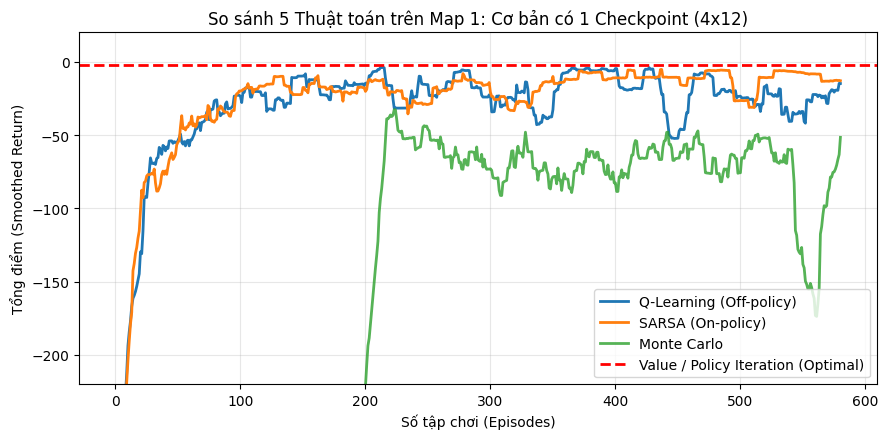


================ ĐANG CHẠY: Map 2: Dài hơn & Nhiều vực hơn (5x14) (|S|=210) ================

--- [Map 2] SARSA (An toàn) (cp_state = 0) ---
 ↓  ↓  →  ↓  →  →  →  →  →  →  →  ↓  ↓  ↓ 
 →  →  ↓  ↓   C   C  ↓  ↑  →  →  →  →  →  ↓ 
 ↑  →  →  →  P↑  →  ↑  ↑   C   C  ↓  →  →  ↓ 
 ↑  ↑  ↑  ↑  →  ↑   C   C  ↑  ←  →  ←  →  ↓ 
 S↑   C   C   C   C   C   C   C   C   C   C   C   C   G 

--- [Map 2] SARSA (Khi ĐÃ CÓ KHIÊN) (cp_state = 1) ---
 ←  →  →  →  →  →  →  →  →  →  ↓  ↓  ↓  ↓ 
 ↓  ←  ↑  ↑   C   C  ↑  ↑  ↑  →  →  →  ↓  ↓ 
 ←  ↓  ↑  ←  P→  →  →  ↑   C   C  →  →  →  ↓ 
 →  ↑  ↑  ←  ↑  ←   C   C  →  ←  ←  →  →  ↓ 
 S↓   C   C   C   C   C   C   C   C   C   C   C   C   G 


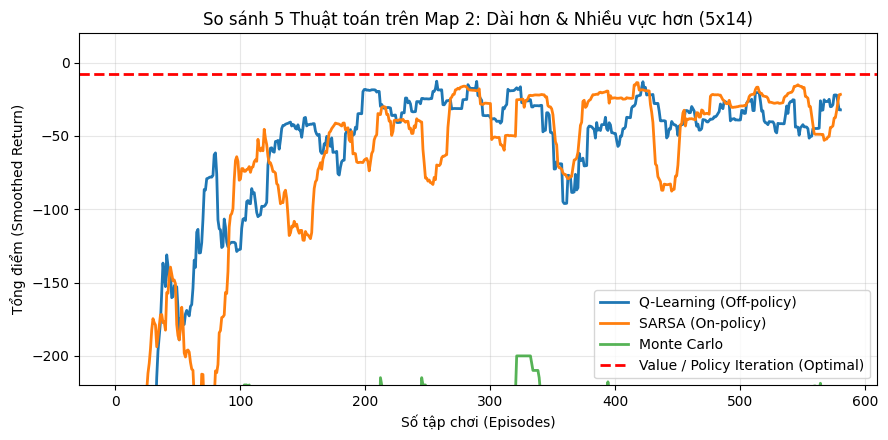


================ ĐANG CHẠY: Map 3: Khó & Vực dày đặc (6x15) (|S|=270) ================

--- [Map 3] SARSA (An toàn) (cp_state = 0) ---
 →  →  →  →  →  →  →  →  →  →  →  →  ↓  ↓  ↓ 
 ←  ↑  ←   C   C  ↑  ↓  ↑  →  ↑   C   C  ↓  ↓  ↓ 
 →  ↑  ↓  →  →  P↑  →  ←  ←   C   C  →  ↓  ↓  ↓ 
 →  ↑  ←  ←  ↑  ↑  ↑   C   C   C  →  →  ↓  →  ↓ 
 ↑  ←  ↑  ↑   C   C  ↑  ←  →  →  →  ↑  →  →  ↓ 
 S↑   C   C   C   C   C   C   C   C   C   C   C   C   C   G 

--- [Map 3] SARSA (Khi ĐÃ CÓ KHIÊN) (cp_state = 1) ---
 ↓  →  →  ←  ←  →  →  →  →  →  →  →  ↓  ↓  ↓ 
 ←  →  ↑   C   C  ↑  →  →  ↑  ↑   C   C  →  ↓  ↓ 
 ↓  ↑  ↓  ←  →  P↓  →  ↑  ↑   C   C  ↓  ↓  →  ↓ 
 →  ↓  ←  ←  ↑  →  ←   C   C   C  →  →  →  ↓  ↓ 
 →  ←  ←  ↑   C   C  →  →  →  →  ↑  ↑  →  →  ↓ 
 S↓   C   C   C   C   C   C   C   C   C   C   C   C   C   G 


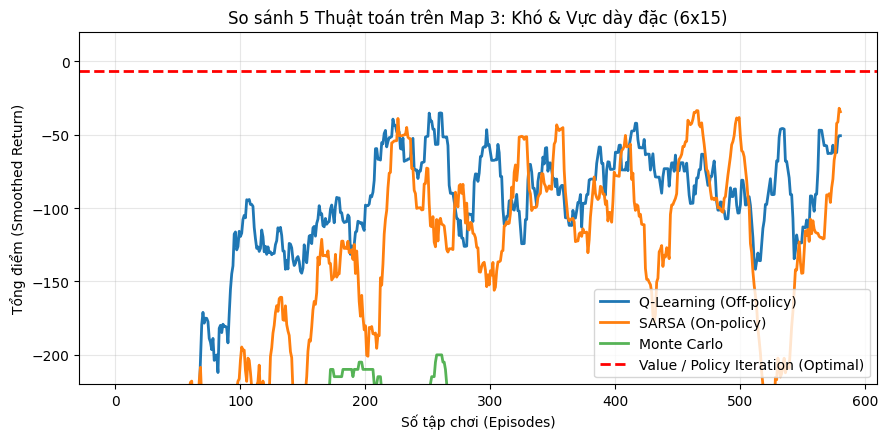

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from maps import MAPS
from env import SimpleCliffEnv
from agents import value_iteration, policy_iteration, monte_carlo, sarsa, q_learning

ARROWS = {0: '↑', 1: '→', 2: '↓', 3: '←'}

def print_policy(env, Q, cp_state=0, title="Policy"):
    print(f"\n--- {title} (cp_state = {cp_state}) ---")
    for r in range(env.H):
        line = ""
        for c in range(env.W):
            ch = env.grid[r][c]
            if ch in ['C', 'G']:
                line += f"  {ch} "
            else:
                s = env.encode_state(r, c, cp_state)
                best_a = int(np.argmax(Q[s]))
                line += f" {ch if ch != '.' else ''}{ARROWS[best_a]} "
        print(line)

def smooth(data, w=20):
    return np.convolve(data, np.ones(w)/w, mode='valid')

# Vòng lặp huấn luyện và hiển thị trực tiếp đồ thị lên màn hình Colab
for idx, map_name in enumerate(MAPS.keys(), start=1):
    env = SimpleCliffEnv(map_name)
    print(f"\n================ ĐANG CHẠY: {map_name} (|S|={env.nS}) ================")

    # Chạy đủ 5 thuật toán
    Q_vi = value_iteration(env)
    Q_pi = policy_iteration(env)
    Q_mc, ret_mc = monte_carlo(env)
    Q_sarsa, ret_sarsa = sarsa(env)
    Q_ql, ret_ql = q_learning(env)

    # In policy mẫu ra màn hình
    print_policy(env, Q_sarsa, 0, f"[Map {idx}] SARSA (An toàn)")
    if env.checkpoint_pos is not None:
        print_policy(env, Q_sarsa, 1, f"[Map {idx}] SARSA (Khi ĐÃ CÓ KHIÊN)")

    # Tính điểm tối ưu của Value Iteration làm đường chuẩn
    s_start = env.encode_state(env.start_pos[0], env.start_pos[1], 0)
    opt_return = 0
    s_sim, _ = env.reset()
    while True:
        a_opt = int(np.argmax(Q_vi[s_sim]))
        s_sim, rew, done, trunc, _ = env.step(a_opt)
        opt_return += rew
        if done or trunc:
            break

    # Vẽ biểu đồ hiển thị ngay trong Colab
    plt.figure(figsize=(9, 4.5))
    plt.plot(smooth(ret_ql), label="Q-Learning (Off-policy)", linewidth=2)
    plt.plot(smooth(ret_sarsa), label="SARSA (On-policy)", linewidth=2)
    plt.plot(smooth(ret_mc), label="Monte Carlo", linewidth=2, alpha=0.8)
    plt.axhline(y=opt_return, color='red', linestyle='--', linewidth=2, label="Value / Policy Iteration (Optimal)")

    plt.title(f"So sánh 5 Thuật toán trên {map_name}")
    plt.xlabel("Số tập chơi (Episodes)")
    plt.ylabel("Tổng điểm (Smoothed Return)")
    plt.ylim(-220, 20)
    plt.legend(loc="lower right")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    # Lệnh này sẽ ép Colab hiển thị ngay hình ảnh ra màn hình
    plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from matplotlib.patches import Rectangle, Circle
from IPython.display import HTML, display
from maps import MAPS
from env import SimpleCliffEnv
from agents import value_iteration, policy_iteration, monte_carlo, sarsa, q_learning

# =========================================================================
# 🎮 BẢNG ĐIỀU KHIỂN DEMO ĐÃ TỐI ƯU HỘI TỤ CHO MAP 2 & MAP 3
# =========================================================================
CHON_MAP_DEMO = "Map 1: Cơ bản có 1 Checkpoint (4x12)" #@param ["Map 1: Cơ bản có 1 Checkpoint (4x12)", "Map 2: Dài hơn & Nhiều vực hơn (5x14)", "Map 3: Khó & Vực dày đặc (6x15)"]
CHON_THUAT_TOAN = "1. Q-Learning (Mạo hiểm - Bám sát vực)" #@param ["1. Q-Learning (Mạo hiểm - Bám sát vực)", "2. SARSA (An toàn - Đi vòng xa vực)", "3. Monte Carlo", "4. Value Iteration", "5. Policy Iteration"]

env = SimpleCliffEnv(CHON_MAP_DEMO)
print(f"Đang huấn luyện chuyên sâu cho [{CHON_MAP_DEMO}] (1500 episodes để đảm bảo chính sách chuẩn xác)...")

# Tăng số tập huấn luyện lên 1500 để chính sách trên Map 2 và Map 3 hội tụ hoàn hảo, không bị đi vòng vô lý
Q_ql = q_learning(env, episodes=1500, alpha=0.15, gamma=0.99, epsilon=0.1)[0]
Q_sarsa = sarsa(env, episodes=1500, alpha=0.15, gamma=0.99, epsilon=0.1)[0]
Q_mc = monte_carlo(env, episodes=1200, alpha=0.1, gamma=0.99, epsilon=0.15)[0]
Q_vi = value_iteration(env)
Q_pi = policy_iteration(env)

bang_Q = {
    "1. Q-Learning (Mạo hiểm - Bám sát vực)": Q_ql,
    "2. SARSA (An toàn - Đi vòng xa vực)": Q_sarsa,
    "3. Monte Carlo": Q_mc,
    "4. Value Iteration": Q_vi,
    "5. Policy Iteration": Q_pi
}

Q_use = bang_Q[CHON_THUAT_TOAN]
ARROWS = {0: '↑', 1: '→', 2: '↓', 3: '←'}

# Mô phỏng đường đi tối ưu từ Start đến Goal
lich_su = []
s, _ = env.reset()
r, c, cp = env.decode_state(s)
tong_diem = 0
lich_su.append((r, c, cp, 0, tong_diem))

for buoc in range(1, 80):
    r_old, c_old, cp_old = env.decode_state(s)
    a = int(np.argmax(Q_use[s]))
    s_moi, diem, xong, _, _ = env.step(a)
    r, c, cp = env.decode_state(s_moi)
    tong_diem += diem
    s = s_moi
    lich_su.append((r, c, cp, buoc, tong_diem))
    if xong:
        break

# Vẽ hoạt ảnh trực quan
fig, ax = plt.subplots(figsize=(10.5, 4.5))
plt.close()

def ve_khung_hinh(i):
    ax.clear()
    r_ag, c_ag, cp_st, buoc, diem = lich_su[i]
    ax.set_xlim(0, env.W)
    ax.set_ylim(0, env.H)
    ax.invert_yaxis()
    ax.set_xticks([])
    ax.set_yticks([])

    for r in range(env.H):
        for c in range(env.W):
            ch = env.grid[r][c]
            if ch == 'C': mau = '#d9383a'      # Vực đỏ
            elif ch == 'S': mau = '#2ea043'    # Start xanh lá
            elif ch == 'G': mau = '#d29922'    # Goal vàng
            elif ch == 'P': mau = '#1f6feb'    # Checkpoint xanh dương
            else: mau = '#30363d'              # Đường thường

            ax.add_patch(Rectangle((c + 0.05, r + 0.05), 0.9, 0.9, facecolor=mau))
            if ch != '.':
                ax.text(c + 0.5, r + 0.5, ch, color='white', ha='center', va='center', fontweight='bold')
            if ch not in ['C', 'G']:
                s_cell = env.encode_state(r, c, cp_st)
                best_a = int(np.argmax(Q_use[s_cell]))
                ax.text(c + 0.2, r + 0.25, ARROWS[best_a], color='lightgray', fontsize=9)

    if cp_st == 1:
        ax.add_patch(Circle((c_ag + 0.5, r_ag + 0.5), 0.38, fill=False, edgecolor='#38bdf8', lw=3.5))

    ax.add_patch(Circle((c_ag + 0.5, r_ag + 0.5), 0.25, facecolor='#10b981', edgecolor='white', lw=2, zorder=5))

    trang_thai_khien = {0: "Chưa có (0)", 1: "ĐANG CÓ KHIÊN BẢO VỆ (1)", 2: "Đã dùng hết khiên (2)"}[cp_st]
    ax.set_title(f"Bản đồ: {CHON_MAP_DEMO}  |  Thuật toán: {CHON_THUAT_TOAN}\nBước: {buoc} | Tổng điểm: {diem} | Trạng thái Khiên: {trang_thai_khien}",
                 fontsize=11, fontweight='bold', pad=10)

anim = animation.FuncAnimation(fig, ve_khung_hinh, frames=len(lich_su), interval=350, repeat=False)
display(HTML(anim.to_jshtml()))

Đang huấn luyện chuyên sâu cho [Map 3: Khó & Vực dày đặc (6x15)] (1500 episodes để đảm bảo chính sách chuẩn xác)...
